<a href="https://colab.research.google.com/github/EstelleYang111/MSSP607/blob/main/WeeklyModules/Week08/Case_Study_Report_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [39]:
import os
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

repo_path = "/content/MSSP607"

if not os.path.exists(repo_path):
    subprocess.run(
        ["git", "clone",
         "https://github.com/EstelleYang111/MSSP607.git",
         repo_path],
        check=True
    )
else:
    subprocess.run(
        ["git", "-C", repo_path, "pull"],
        check=True
    )

os.chdir(repo_path)

df = pd.read_csv(
    "data/week08/InternetSales.csv",
    encoding="cp1252",
    low_memory=False
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (60398, 60)


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [40]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).head(15))

df["OrderDate"] = pd.to_datetime(df["OrderDate"])

print("\nEarliest order:", df["OrderDate"].min())
print("Latest order:", df["OrderDate"].max())


Column names:
['ID', 'CustomerKey', 'GeographyKey', 'City', 'CountryRegionCode', 'EnglishCountryRegionName', 'CustomerAlternateKey', 'Title', 'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate', 'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'YearlyIncome', 'TotalChildren', 'NumberChildrenAtHome', 'EnglishEducation', 'SpanishEducation', 'FrenchEducation', 'EnglishOccupation', 'SpanishOccupation', 'FrenchOccupation', 'HouseOwnerFlag', 'NumberCarsOwned', 'AddressLine1', 'AddressLine2', 'Phone', 'DateFirstPurchase', 'CommuteDistance', 'ProductKey', 'EnglishProductName', 'OrderDateKey', 'DueDateKey', 'ShipDateKey', 'CustomerKey.1', 'PromotionKey', 'CurrencyKey', 'SalesTerritoryKey', 'SalesOrderNumber', 'SalesOrderLineNumber', 'RevisionNumber', 'OrderQuantity', 'UnitPrice', 'ExtendedAmount', 'UnitPriceDiscountPct', 'DiscountAmount', 'ProductStandardCost', 'TotalProductCost', 'SalesAmount', 'TaxAmt', 'Freight', 'CarrierTrackingNumber', 'CustomerPONumber', 'OrderDate', 'DueD

,0
CustomerPONumber,60398
CarrierTrackingNumber,60398
Suffix,60392
Title,60091
AddressLine2,59293
MiddleName,25495
City,0
CountryRegionCode,0
CustomerAlternateKey,0
GeographyKey,0



Earliest order: 2010-12-29 00:00:00
Latest order: 2014-01-28 00:00:00


In [41]:
# Question 1: Internet Sales by Year and Country Region

# Extract year from order date
df["OrderDate"] = pd.to_datetime(df["OrderDate"])
df["Year"] = df["OrderDate"].dt.year

# Summarize annual sales by country
annual_sales = (
    df.groupby(
        ["EnglishCountryRegionName", "Year"]
    )["SalesAmount"]
    .sum()
    .unstack(fill_value=0)
)

print("Annual Internet Sales by Country Region (USD)")
display(annual_sales.round(2))

Annual Internet Sales by Country Region (USD)


Year,2010,2011,2012,2013,2014
EnglishCountryRegionName,,,,,
Australia,20909.78,2563732.25,2128407.46,4339443.38,8507.72
Canada,3578.27,571571.80,307604.52,1085632.65,9457.62
France,3399.99,410845.33,648065.54,1578511.80,3195.06
Germany,0.00,520500.16,608657.98,1761876.36,3277.83
United Kingdom,699.10,550591.22,712700.96,2124007.29,3713.64
United States,14833.90,2458285.17,1437048.73,5462078.86,17542.85


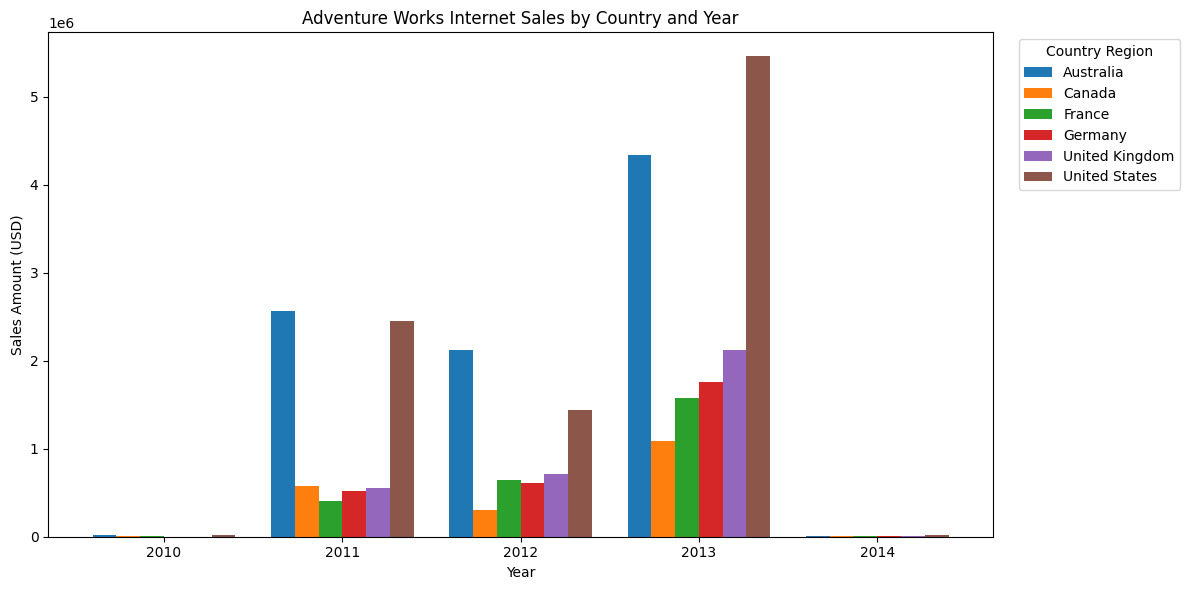

In [42]:
# Plot annual sales by country

annual_sales.T.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Adventure Works Internet Sales by Country and Year")
plt.xlabel("Year")
plt.ylabel("Sales Amount (USD)")
plt.xticks(rotation=0)
plt.legend(
    title="Country Region",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

In [43]:
# Rank country regions using complete years

complete_years = df[df["Year"].between(2011, 2013)]

country_ranking = (
    complete_years.groupby("EnglishCountryRegionName")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Internet Sales by Country (2011–2013)")
display(country_ranking.round(2))

Total Internet Sales by Country (2011–2013)


,SalesAmount
EnglishCountryRegionName,
United States,9357412.76
Australia,9031583.08
United Kingdom,3387299.47
Germany,2891034.51
France,2637422.66
Canada,1964808.97


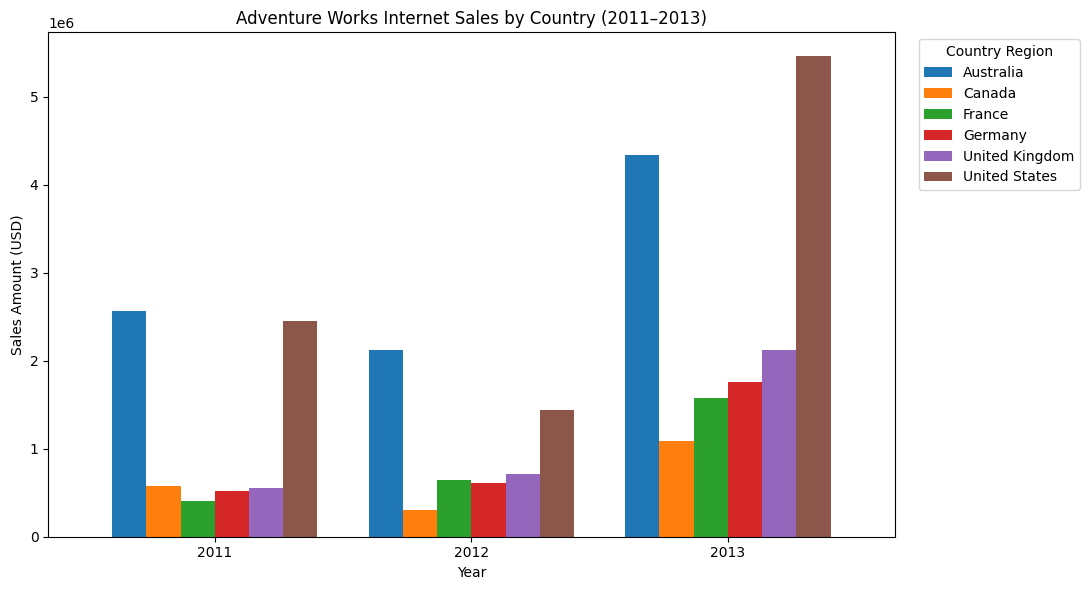

In [44]:
# Sales comparison for complete years only (2011–2013)

annual_sales[[2011, 2012, 2013]].T.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Adventure Works Internet Sales by Country (2011–2013)")
plt.xlabel("Year")
plt.ylabel("Sales Amount (USD)")
plt.xticks(rotation=0)
plt.legend(
    title="Country Region",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

In [45]:
# Question 2: Customer Demographics

# Keep one record per customer
customers = df.drop_duplicates(subset="CustomerKey").copy()

# Check the number of unique customers
print("Number of unique customers:", len(customers))

Number of unique customers: 18484


In [46]:
# Yearly Income Summary Statistics by Country Region

income_summary = (
    customers.groupby("EnglishCountryRegionName")["YearlyIncome"]
    .agg(["count", "min", "max", "mean", "median", "std"])
    .round(2)
)

print("Yearly Income Summary by Country Region")
display(income_summary)

Yearly Income Summary by Country Region


,count,min,max,mean,median,std
EnglishCountryRegionName,,,,,,
Australia,3591,10000,170000,64338.62,70000.0,31830.00
Canada,1571,10000,170000,57167.41,60000.0,20251.52
France,1810,10000,110000,35762.43,30000.0,27277.40
Germany,1780,10000,130000,42943.82,30000.0,35493.58
United Kingdom,1913,10000,170000,52169.37,30000.0,48431.99
United States,7819,10000,170000,63616.83,60000.0,25706.48


In [47]:
# Gender Counts by Country Region

gender_counts = pd.crosstab(
    customers["EnglishCountryRegionName"],
    customers["Gender"]
)

print("Gender Counts by Country Region")
display(gender_counts)

Gender Counts by Country Region


Gender,F,M
EnglishCountryRegionName,,
Australia,1777,1814
Canada,767,804
France,893,917
Germany,874,906
United Kingdom,934,979
United States,3888,3931


In [48]:
# Gender Percentages by Country Region

gender_percentages = (
    pd.crosstab(
        customers["EnglishCountryRegionName"],
        customers["Gender"],
        normalize="index"
    ) * 100
).round(2)

print("Gender Distribution (%) by Country Region")
display(gender_percentages)

Gender Distribution (%) by Country Region


Gender,F,M
EnglishCountryRegionName,,
Australia,49.48,50.52
Canada,48.82,51.18
France,49.34,50.66
Germany,49.10,50.90
United Kingdom,48.82,51.18
United States,49.73,50.27


In [49]:
# Question 3: Explore product information

# Count unique products
print("Number of unique products:")
print(df["EnglishProductName"].nunique())

# Display product names
product_names = sorted(df["EnglishProductName"].dropna().unique())

for name in product_names:
    print(name)

Number of unique products:
130
AWC Logo Cap
All-Purpose Bike Stand
Bike Wash - Dissolver
Classic Vest, L
Classic Vest, M
Classic Vest, S
Fender Set - Mountain
HL Mountain Tire
HL Road Tire
Half-Finger Gloves, L
Half-Finger Gloves, M
Half-Finger Gloves, S
Hitch Rack - 4-Bike
Hydration Pack - 70 oz.
LL Mountain Tire
LL Road Tire
Long-Sleeve Logo Jersey, L
Long-Sleeve Logo Jersey, M
Long-Sleeve Logo Jersey, S
Long-Sleeve Logo Jersey, XL
ML Mountain Tire
ML Road Tire
Mountain Bottle Cage
Mountain Tire Tube
Mountain-100 Black, 38
Mountain-100 Black, 42
Mountain-100 Black, 44
Mountain-100 Black, 48
Mountain-100 Silver, 38
Mountain-100 Silver, 42
Mountain-100 Silver, 44
Mountain-100 Silver, 48
Mountain-200 Black, 38
Mountain-200 Black, 42
Mountain-200 Black, 46
Mountain-200 Silver, 38
Mountain-200 Silver, 42
Mountain-200 Silver, 46
Mountain-400-W Silver, 38
Mountain-400-W Silver, 40
Mountain-400-W Silver, 42
Mountain-400-W Silver, 46
Mountain-500 Black, 40
Mountain-500 Black, 42
Mountain-500 

In [50]:
# Question 3: Explore product name patterns

product_prefixes = (
    df["EnglishProductName"]
    .str.split("-", n=1)
    .str[0]
    .value_counts()
)

display(product_prefixes)

,count
EnglishProductName,
Road,8068
Sport,6440
Mountain,4970
Water Bottle,4244
Patch Kit/8 Patches,3191
Mountain Tire Tube,3095
Road Tire Tube,2376
AWC Logo Cap,2190
Touring,2167


In [51]:
# Question 3: Classify products into categories

def classify_product(name):
    name = str(name).lower()

    # Bikes
    if name.startswith(("mountain-", "road-", "touring-")):
        return "Bikes"

    # Clothing
    clothing_keywords = [
        "jersey", "shorts", "gloves", "socks",
        "cap", "vest"
    ]
    if any(word in name for word in clothing_keywords):
        return "Clothing"

    # Accessories
    accessory_keywords = [
        "helmet", "tire", "tube", "bottle",
        "cage", "pump", "fender", "lock",
        "hydration", "patch kit", "bike wash",
        "hitch rack", "all-purpose"
    ]
    if any(word in name for word in accessory_keywords):
        return "Accessories"

    return "Unclassified"

df["ProductCategory"] = (
    df["EnglishProductName"].apply(classify_product)
)

print("Product Category Counts:")
display(df["ProductCategory"].value_counts())

print("\nUnclassified Products:")
display(
    df.loc[
        df["ProductCategory"] == "Unclassified",
        "EnglishProductName"
    ].drop_duplicates().sort_values()
)

Product Category Counts:


,count
ProductCategory,
Accessories,36092
Bikes,15205
Clothing,9101



Unclassified Products:


,EnglishProductName


In [52]:
# Question 3: Total Sales by Product Category

category_sales = (
    df.groupby("ProductCategory")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Sales by Product Category (USD)")
display(category_sales.round(2))

Total Sales by Product Category (USD)


,SalesAmount
ProductCategory,
Bikes,28318144.65
Accessories,700759.96
Clothing,339772.61


In [53]:
# Identify the category with the highest sales

top_category = category_sales.idxmax()

# Select sales records from that category
top_category_data = df[
    df["ProductCategory"] == top_category
]

# Calculate average unit price
average_price = top_category_data["UnitPrice"].mean()

# Calculate quantity-weighted average selling price
weighted_average_price = (
    top_category_data["SalesAmount"].sum()
    / top_category_data["OrderQuantity"].sum()
)

print("Highest-Sales Product Category:", top_category)
print(f"Average Unit Price: ${average_price:,.2f}")
print(f"Average Selling Price per Unit: ${weighted_average_price:,.2f}")

Highest-Sales Product Category: Bikes
Average Unit Price: $1,862.42
Average Selling Price per Unit: $1,862.42


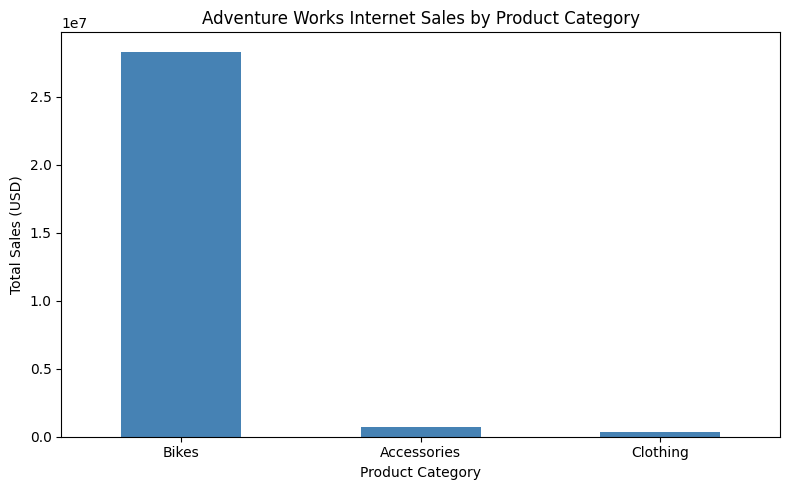

In [54]:
# Visualize sales by product category

category_sales.plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue"
)

plt.title("Adventure Works Internet Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales (USD)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [55]:
# Question 4: Homeownership and Internet Sales

# Calculate total spending for each customer
customer_sales = (
    df.groupby("CustomerKey")
    .agg(
        TotalSpending=("SalesAmount", "sum"),
        HouseOwnerFlag=("HouseOwnerFlag", "first")
    )
    .reset_index()
)

# Compare homeowners and non-homeowners
homeowner_summary = (
    customer_sales.groupby("HouseOwnerFlag")["TotalSpending"]
    .agg(["count", "sum", "mean", "median", "std"])
    .round(2)
)

homeowner_summary.index = homeowner_summary.index.map({
    0: "Non-Homeowners",
    1: "Homeowners"
})

print("Internet Sales by Homeownership Status")
display(homeowner_summary)

Internet Sales by Homeownership Status


,count,sum,mean,median,std
HouseOwnerFlag,,,,,
Non-Homeowners,5982,8973327.42,1500.05,209.96,2046.88
Homeowners,12502,20385349.80,1630.57,342.00,2159.07


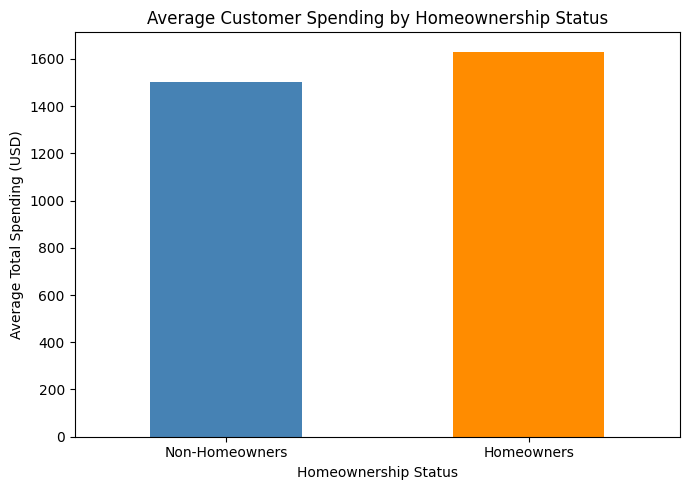

In [56]:
# Compare average spending by homeownership

homeowner_summary["mean"].plot(
    kind="bar",
    figsize=(7, 5),
    color=["steelblue", "darkorange"]
)

plt.title("Average Customer Spending by Homeownership Status")
plt.xlabel("Homeownership Status")
plt.ylabel("Average Total Spending (USD)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [57]:
# Additional Analysis: Product Category Sales by Country

category_country_sales = (
    df[df["Year"].between(2011, 2013)]
    .pivot_table(
        index="EnglishCountryRegionName",
        columns="ProductCategory",
        values="SalesAmount",
        aggfunc="sum",
        fill_value=0
    )
)

print("Product Category Sales by Country (2011–2013)")
display(category_country_sales.round(2))

Product Category Sales by Country (2011–2013)


ProductCategory,Accessories,Bikes,Clothing
EnglishCountryRegionName,,,
Australia,133337.20,8831140.22,67105.66
Canada,96979.01,1817724.12,50105.84
France,61041.93,2550175.72,26205.01
Germany,59748.56,2808514.35,22771.60
United Kingdom,74246.09,3282143.56,30909.82
United States,245035.82,8985025.63,127351.31
